In [5]:
df.isnull().sum()

UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9)

In [3]:
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../dataset/ai4i2020.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (10000, 14)


In [6]:
df["Machine failure"].value_counts()

0    9661
1     339
Name: Machine failure, dtype: int64

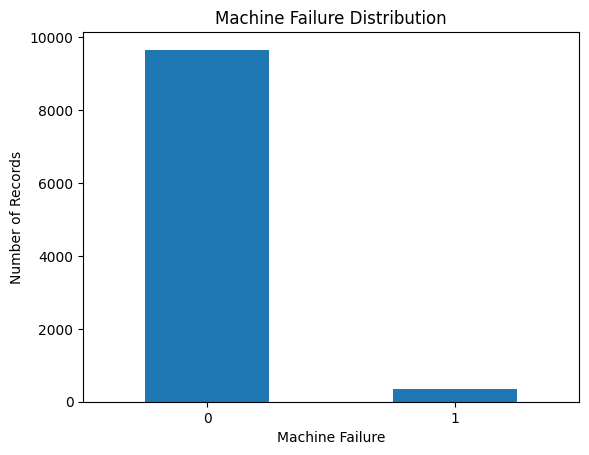

In [7]:
import matplotlib.pyplot as plt

df["Machine failure"].value_counts().plot(kind="bar")

plt.title("Machine Failure Distribution")
plt.xlabel("Machine Failure")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.show()

In [8]:
df[[
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]].describe()

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,300.004930,310.005560,1538.776100,39.986910,107.951000
std,2.000259,1.483734,179.284096,9.968934,63.654147
min,295.300000,305.700000,1168.000000,3.800000,0.000000
25%,298.300000,308.800000,1423.000000,33.200000,53.000000
50%,300.100000,310.100000,1503.000000,40.100000,108.000000
75%,301.500000,311.100000,1612.000000,46.800000,162.000000
max,304.500000,313.800000,2886.000000,76.600000,253.000000


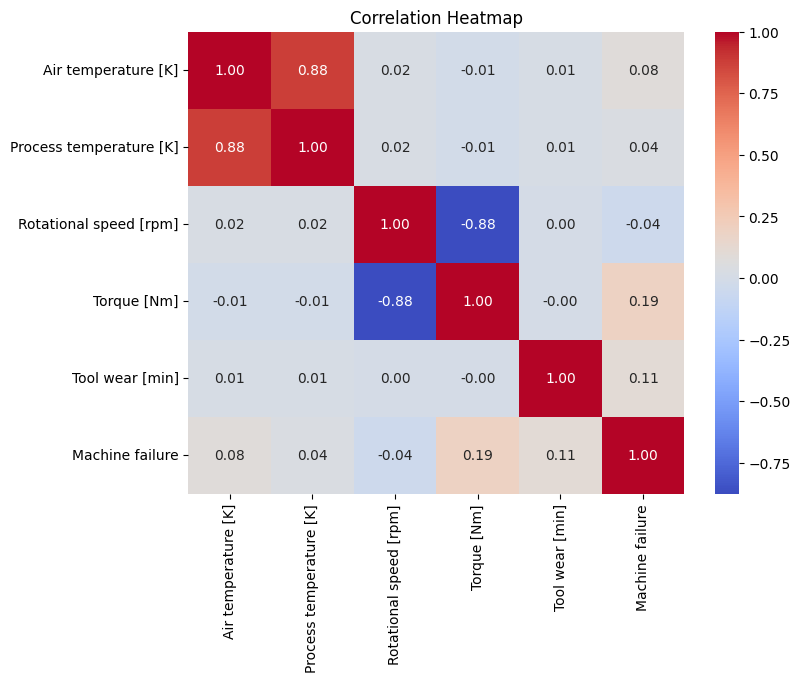

In [9]:
import seaborn as sns
import matplotlib.pyplot as plt

numeric_cols = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
    "Machine failure"
]

correlation = df[numeric_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

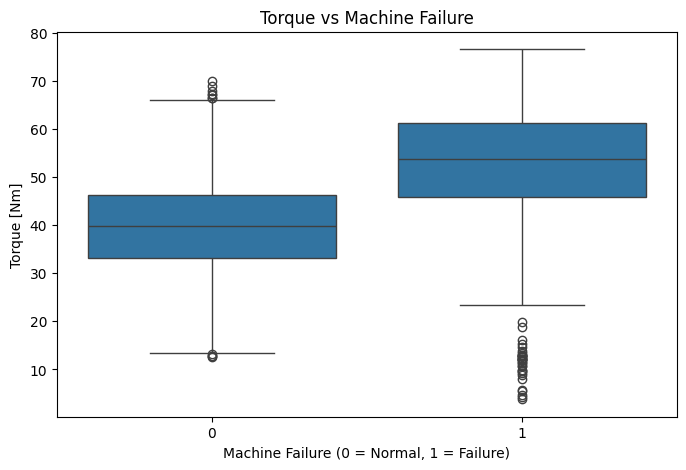

In [10]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    x="Machine failure",
    y="Torque [Nm]",
    data=df
)

plt.title("Torque vs Machine Failure")
plt.xlabel("Machine Failure (0 = Normal, 1 = Failure)")
plt.ylabel("Torque [Nm]")
plt.show()

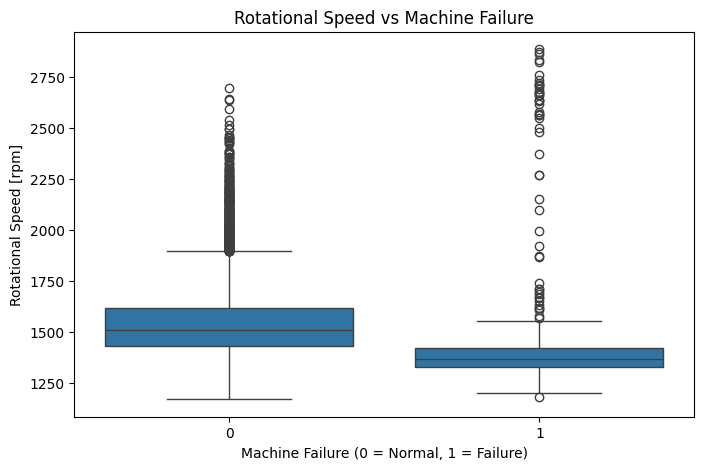

In [11]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    x="Machine failure",
    y="Rotational speed [rpm]",
    data=df
)

plt.title("Rotational Speed vs Machine Failure")
plt.xlabel("Machine Failure (0 = Normal, 1 = Failure)")
plt.ylabel("Rotational Speed [rpm]")
plt.show()

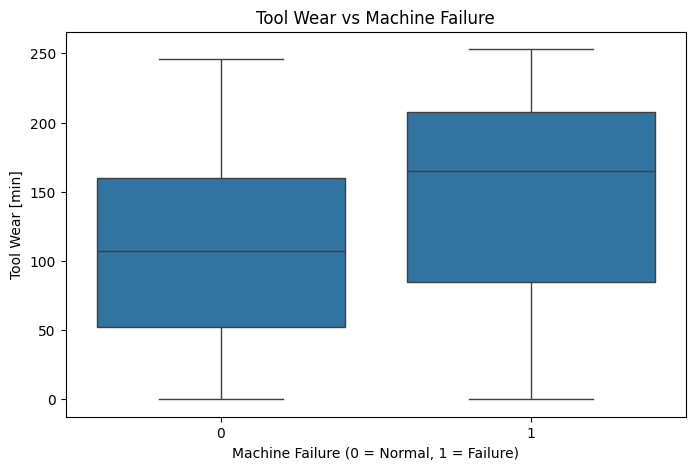

In [12]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    x="Machine failure",
    y="Tool wear [min]",
    data=df
)

plt.title("Tool Wear vs Machine Failure")
plt.xlabel("Machine Failure (0 = Normal, 1 = Failure)")
plt.ylabel("Tool Wear [min]")
plt.show()

In [13]:
features = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

X = df[features]
y = df["Machine failure"]

print("Features:")
print(X.columns.tolist())

print("\nTarget:")
print(y.name)

print("\nFeature shape:", X.shape)
print("Target shape:", y.shape)

Features:
['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']

Target:
Machine failure

Feature shape: (10000, 6)
Target shape: (10000,)


In [14]:
print(df["Type"].value_counts())

L    6000
M    2997
H    1003
Name: Type, dtype: int64


In [15]:
categorical_features = ["Type"]

numerical_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

print("Categorical features:", categorical_features)
print("Numerical features:", numerical_features)

Categorical features: ['Type']
Numerical features: ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']


In [16]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

print("Preprocessor created successfully!")

Preprocessor created successfully!


In [17]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (8000, 6)
Testing data: (2000, 6)


In [18]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Preprocessing completed!")
print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Preprocessing completed!
Processed training shape: (8000, 8)
Processed testing shape: (2000, 8)


In [19]:
print("Training target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training target distribution:
0    7729
1     271
Name: Machine failure, dtype: int64

Testing target distribution:
0    1932
1      68
Name: Machine failure, dtype: int64


In [20]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(X_train_processed, y_train)

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


In [21]:
y_pred_lr = logistic_model.predict(X_test_processed)

print("Predictions completed!")
print(y_pred_lr[:20])

Predictions completed!
[1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [22]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

accuracy = accuracy_score(y_test, y_pred_lr)
precision = precision_score(y_test, y_pred_lr, zero_division=0)
recall = recall_score(y_test, y_pred_lr, zero_division=0)
f1 = f1_score(y_test, y_pred_lr, zero_division=0)

print("Logistic Regression Results")
print("---------------------------")
print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1-Score :", f1)

Logistic Regression Results
---------------------------
Accuracy : 0.9675
Precision: 0.6363636363636364
Recall   : 0.10294117647058823
F1-Score : 0.17721518987341772


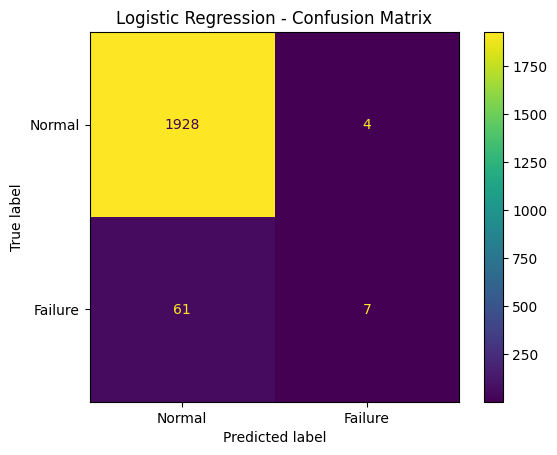

In [23]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred_lr)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Failure"]
)

disp.plot()
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [24]:
results = []

results.append({
    "Model": "Logistic Regression",
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1-Score": f1
})

print(results)

[{'Model': 'Logistic Regression', 'Accuracy': 0.9675, 'Precision': 0.6363636363636364, 'Recall': 0.10294117647058823, 'F1-Score': 0.17721518987341772}]


In [25]:
from sklearn.tree import DecisionTreeClassifier

decision_tree = DecisionTreeClassifier(
    random_state=42,
    class_weight="balanced"
)

decision_tree.fit(X_train_processed, y_train)

y_pred_dt = decision_tree.predict(X_test_processed)

print("Decision Tree trained successfully!")

Decision Tree trained successfully!


In [26]:
accuracy_dt = accuracy_score(y_test, y_pred_dt)
precision_dt = precision_score(y_test, y_pred_dt, zero_division=0)
recall_dt = recall_score(y_test, y_pred_dt, zero_division=0)
f1_dt = f1_score(y_test, y_pred_dt, zero_division=0)

print("Decision Tree Results")
print("---------------------")
print("Accuracy :", accuracy_dt)
print("Precision:", precision_dt)
print("Recall   :", recall_dt)
print("F1-Score :", f1_dt)

Decision Tree Results
---------------------
Accuracy : 0.9775
Precision: 0.6949152542372882
Recall   : 0.6029411764705882
F1-Score : 0.6456692913385826


In [27]:
results.append({
    "Model": "Decision Tree",
    "Accuracy": accuracy_dt,
    "Precision": precision_dt,
    "Recall": recall_dt,
    "F1-Score": f1_dt
})

print(results)

[{'Model': 'Logistic Regression', 'Accuracy': 0.9675, 'Precision': 0.6363636363636364, 'Recall': 0.10294117647058823, 'F1-Score': 0.17721518987341772}, {'Model': 'Decision Tree', 'Accuracy': 0.9775, 'Precision': 0.6949152542372882, 'Recall': 0.6029411764705882, 'F1-Score': 0.6456692913385826}]


In [28]:
from sklearn.ensemble import RandomForestClassifier

random_forest = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
)

random_forest.fit(X_train_processed, y_train)

y_pred_rf = random_forest.predict(X_test_processed)

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [29]:
accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf, zero_division=0)
recall_rf = recall_score(y_test, y_pred_rf, zero_division=0)
f1_rf = f1_score(y_test, y_pred_rf, zero_division=0)

print("Random Forest Results")
print("---------------------")
print("Accuracy :", accuracy_rf)
print("Precision:", precision_rf)
print("Recall   :", recall_rf)
print("F1-Score :", f1_rf)

Random Forest Results
---------------------
Accuracy : 0.979
Precision: 0.90625
Recall   : 0.4264705882352941
F1-Score : 0.58


In [30]:
results.append({
    "Model": "Random Forest",
    "Accuracy": accuracy_rf,
    "Precision": precision_rf,
    "Recall": recall_rf,
    "F1-Score": f1_rf
})

print(results)

[{'Model': 'Logistic Regression', 'Accuracy': 0.9675, 'Precision': 0.6363636363636364, 'Recall': 0.10294117647058823, 'F1-Score': 0.17721518987341772}, {'Model': 'Decision Tree', 'Accuracy': 0.9775, 'Precision': 0.6949152542372882, 'Recall': 0.6029411764705882, 'F1-Score': 0.6456692913385826}, {'Model': 'Random Forest', 'Accuracy': 0.979, 'Precision': 0.90625, 'Recall': 0.4264705882352941, 'F1-Score': 0.58}]


In [31]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.05,
    random_state=42,
    eval_metric="logloss"
)

xgb_model.fit(X_train_processed, y_train)

y_pred_xgb = xgb_model.predict(X_test_processed)

print("XGBoost trained successfully!")

XGBoost trained successfully!


In [32]:
accuracy_xgb = accuracy_score(y_test, y_pred_xgb)
precision_xgb = precision_score(y_test, y_pred_xgb, zero_division=0)
recall_xgb = recall_score(y_test, y_pred_xgb, zero_division=0)
f1_xgb = f1_score(y_test, y_pred_xgb, zero_division=0)

print("XGBoost Results")
print("----------------")
print("Accuracy :", accuracy_xgb)
print("Precision:", precision_xgb)
print("Recall   :", recall_xgb)
print("F1-Score :", f1_xgb)

XGBoost Results
----------------
Accuracy : 0.987
Precision: 0.9038461538461539
Recall   : 0.6911764705882353
F1-Score : 0.7833333333333333


In [33]:
results.append({
    "Model": "XGBoost",
    "Accuracy": accuracy_xgb,
    "Precision": precision_xgb,
    "Recall": recall_xgb,
    "F1-Score": f1_xgb
})

print(results)

[{'Model': 'Logistic Regression', 'Accuracy': 0.9675, 'Precision': 0.6363636363636364, 'Recall': 0.10294117647058823, 'F1-Score': 0.17721518987341772}, {'Model': 'Decision Tree', 'Accuracy': 0.9775, 'Precision': 0.6949152542372882, 'Recall': 0.6029411764705882, 'F1-Score': 0.6456692913385826}, {'Model': 'Random Forest', 'Accuracy': 0.979, 'Precision': 0.90625, 'Recall': 0.4264705882352941, 'F1-Score': 0.58}, {'Model': 'XGBoost', 'Accuracy': 0.987, 'Precision': 0.9038461538461539, 'Recall': 0.6911764705882353, 'F1-Score': 0.7833333333333333}]


In [34]:
from sklearn.ensemble import VotingClassifier

hybrid_model = VotingClassifier(
    estimators=[
        ("dt", decision_tree),
        ("rf", random_forest),
        ("xgb", xgb_model)
    ],
    voting="soft"
)

hybrid_model.fit(X_train_processed, y_train)

y_pred_hybrid = hybrid_model.predict(X_test_processed)

print("Hybrid model trained successfully!")

Hybrid model trained successfully!


In [35]:
accuracy_hybrid = accuracy_score(y_test, y_pred_hybrid)
precision_hybrid = precision_score(y_test, y_pred_hybrid, zero_division=0)
recall_hybrid = recall_score(y_test, y_pred_hybrid, zero_division=0)
f1_hybrid = f1_score(y_test, y_pred_hybrid, zero_division=0)

print("Hybrid Model Results")
print("--------------------")
print("Accuracy :", accuracy_hybrid)
print("Precision:", precision_hybrid)
print("Recall   :", recall_hybrid)
print("F1-Score :", f1_hybrid)

Hybrid Model Results
--------------------
Accuracy : 0.983
Precision: 0.8541666666666666
Recall   : 0.6029411764705882
F1-Score : 0.7068965517241379


In [36]:
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

print("Scale Pos Weight:", scale_pos_weight)

Scale Pos Weight: 28.52029520295203


In [37]:
from xgboost import XGBClassifier

xgb_balanced = XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.05,
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    eval_metric="logloss"
)

xgb_balanced.fit(X_train_processed, y_train)

y_pred_xgb_balanced = xgb_balanced.predict(X_test_processed)

print("Balanced XGBoost trained successfully!")

Balanced XGBoost trained successfully!


In [38]:
accuracy_xgb_balanced = accuracy_score(y_test, y_pred_xgb_balanced)
precision_xgb_balanced = precision_score(
    y_test, y_pred_xgb_balanced, zero_division=0
)
recall_xgb_balanced = recall_score(
    y_test, y_pred_xgb_balanced, zero_division=0
)
f1_xgb_balanced = f1_score(
    y_test, y_pred_xgb_balanced, zero_division=0
)

print("Balanced XGBoost Results")
print("------------------------")
print("Accuracy :", accuracy_xgb_balanced)
print("Precision:", precision_xgb_balanced)
print("Recall   :", recall_xgb_balanced)
print("F1-Score :", f1_xgb_balanced)

Balanced XGBoost Results
------------------------
Accuracy : 0.969
Precision: 0.5288461538461539
Recall   : 0.8088235294117647
F1-Score : 0.6395348837209303


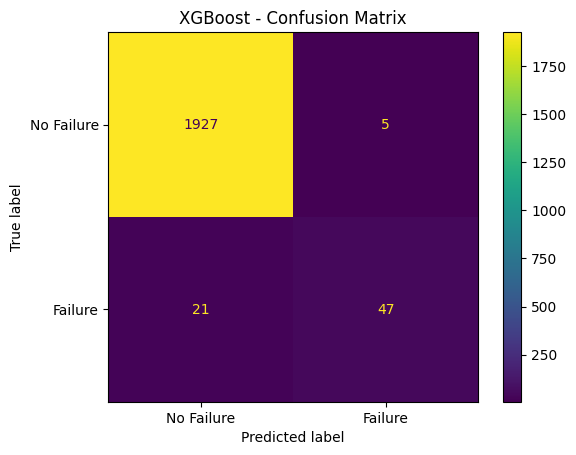

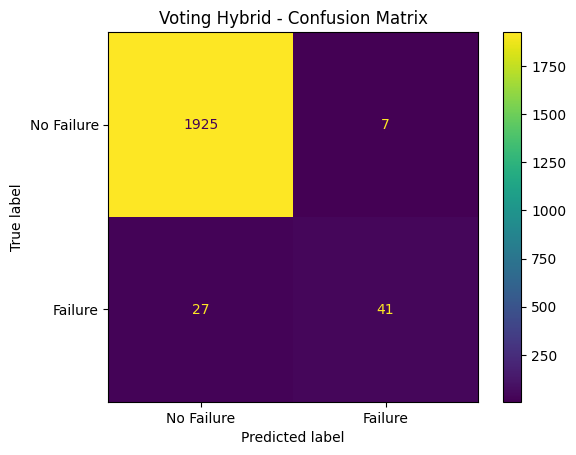

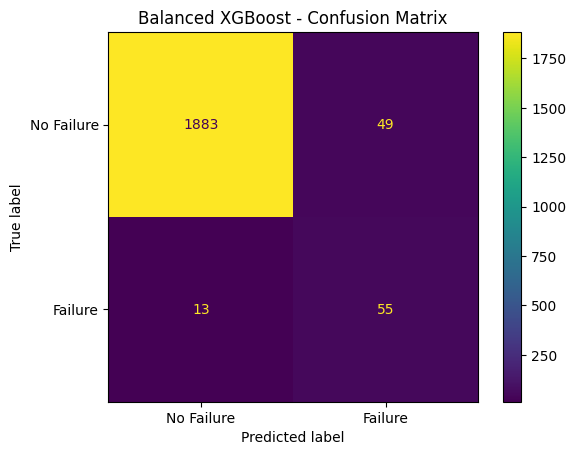

In [39]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

models_to_compare = {
    "XGBoost": y_pred_xgb,
    "Voting Hybrid": y_pred_hybrid,
    "Balanced XGBoost": y_pred_xgb_balanced
}

for name, predictions in models_to_compare.items():
    cm = confusion_matrix(y_test, predictions)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No Failure", "Failure"]
    )

    disp.plot()
    plt.title(f"{name} - Confusion Matrix")
    plt.show()

In [40]:
results.append({
    "Model": "Voting Hybrid",
    "Accuracy": accuracy_hybrid,
    "Precision": precision_hybrid,
    "Recall": recall_hybrid,
    "F1-Score": f1_hybrid
})

results.append({
    "Model": "Balanced XGBoost",
    "Accuracy": accuracy_xgb_balanced,
    "Precision": precision_xgb_balanced,
    "Recall": recall_xgb_balanced,
    "F1-Score": f1_xgb_balanced
})

results_df = pd.DataFrame(results)

results_df

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.9675,0.636364,0.102941,0.177215
1,Decision Tree,0.9775,0.694915,0.602941,0.645669
2,Random Forest,0.9790,0.906250,0.426471,0.580000
3,XGBoost,0.9870,0.903846,0.691176,0.783333
4,Voting Hybrid,0.9830,0.854167,0.602941,0.706897
5,Balanced XGBoost,0.9690,0.528846,0.808824,0.639535


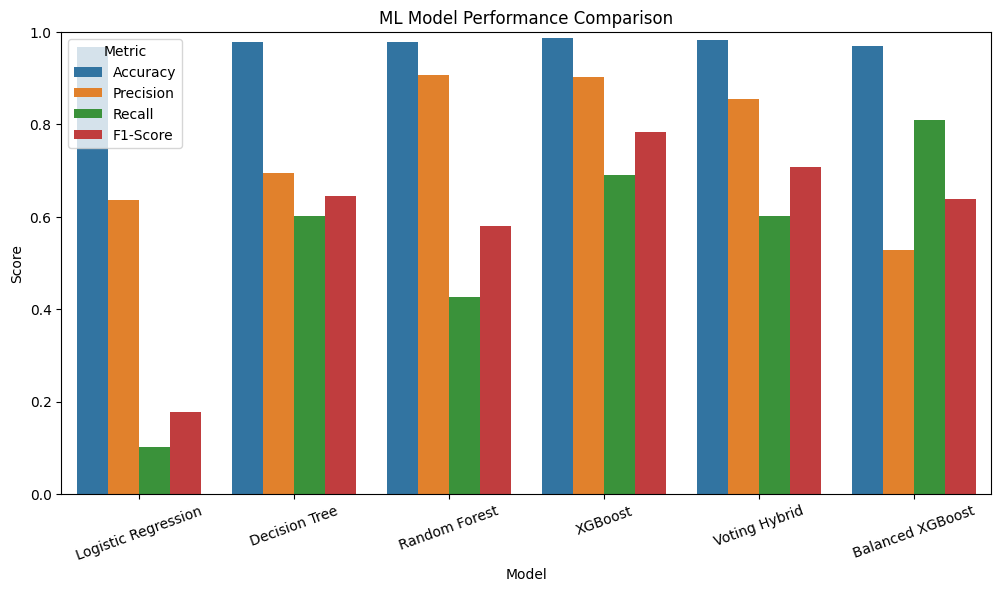

In [41]:
results_melted = results_df.melt(
    id_vars="Model",
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_melted,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.ylim(0, 1)
plt.title("ML Model Performance Comparison")
plt.xlabel("Model")
plt.ylabel("Score")
plt.xticks(rotation=20)
plt.legend(title="Metric")
plt.show()

In [42]:
# Get feature names after preprocessing

feature_names = preprocessor.get_feature_names_out()

# Get XGBoost feature importance
importance = xgb_model.feature_importances_

# Create DataFrame
feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

# Sort by importance
feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
)

feature_importance_df

,Feature,Importance
3,num__Torque [Nm],0.261699
2,num__Rotational speed [rpm],0.181908
4,num__Tool wear [min],0.162323
0,num__Air temperature [K],0.145497
1,num__Process temperature [K],0.086757
7,cat__Type_M,0.074518
5,cat__Type_H,0.044680
6,cat__Type_L,0.042618


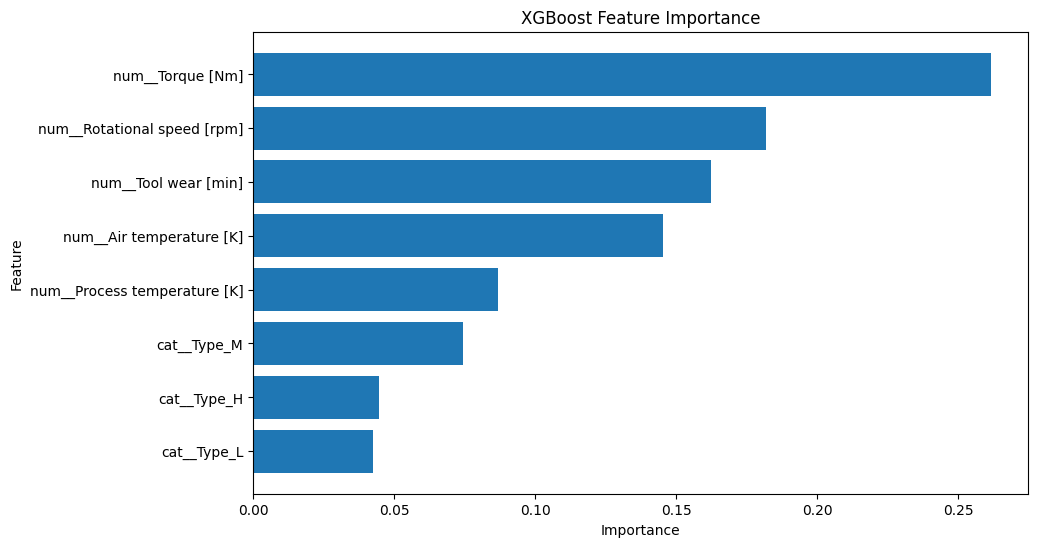

In [43]:
plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance_df["Feature"],
    feature_importance_df["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("XGBoost Feature Importance")
plt.gca().invert_yaxis()

plt.show()

In [44]:
from sklearn.metrics import roc_auc_score, roc_curve

# Get prediction probabilities
y_prob_xgb = xgb_model.predict_proba(X_test_processed)[:, 1]
y_prob_hybrid = hybrid_model.predict_proba(X_test_processed)[:, 1]

# Calculate ROC-AUC
auc_xgb = roc_auc_score(y_test, y_prob_xgb)
auc_hybrid = roc_auc_score(y_test, y_prob_hybrid)

print("XGBoost ROC-AUC :", auc_xgb)
print("Voting Hybrid ROC-AUC :", auc_hybrid)

XGBoost ROC-AUC : 0.9768222506393862
Voting Hybrid ROC-AUC : 0.9728869808793082


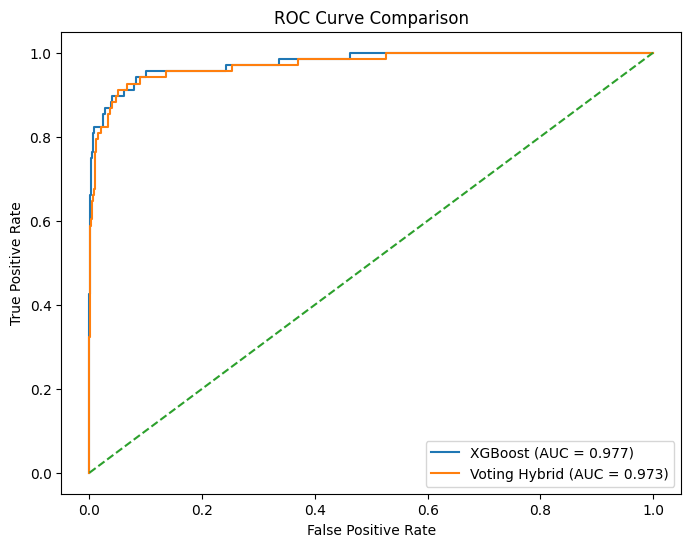

In [45]:
from sklearn.metrics import roc_curve

# ROC curve for XGBoost
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, y_prob_xgb)

# ROC curve for Voting Hybrid
fpr_hybrid, tpr_hybrid, _ = roc_curve(y_test, y_prob_hybrid)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr_xgb,
    tpr_xgb,
    label=f"XGBoost (AUC = {auc_xgb:.3f})"
)

plt.plot(
    fpr_hybrid,
    tpr_hybrid,
    label=f"Voting Hybrid (AUC = {auc_hybrid:.3f})"
)

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.show()

In [46]:
import joblib
import os

# Create models folder if it doesn't exist
os.makedirs("../models", exist_ok=True)

# Create a pipeline using the already fitted preprocessor and XGBoost model
from sklearn.pipeline import Pipeline

final_model = Pipeline([
    ("preprocessor", preprocessor),
    ("xgboost", xgb_model)
])

# Save the complete model
joblib.dump(
    final_model,
    "../models/predictive_maintenance_xgboost.pkl"
)

print("Final model saved successfully!")

Final model saved successfully!


In [47]:
import os

model_path = "../models/predictive_maintenance_xgboost.pkl"

if os.path.exists(model_path):
    print("Model file exists!")
    print("Location:", model_path)
else:
    print("Model file not found.")

Model file exists!
Location: ../models/predictive_maintenance_xgboost.pkl


In [48]:
def predict_machine_failure(
    machine_type,
    air_temperature,
    process_temperature,
    rotational_speed,
    torque,
    tool_wear
):
    # Create input DataFrame
    input_data = pd.DataFrame({
        "Type": [machine_type],
        "Air temperature [K]": [air_temperature],
        "Process temperature [K]": [process_temperature],
        "Rotational speed [rpm]": [rotational_speed],
        "Torque [Nm]": [torque],
        "Tool wear [min]": [tool_wear]
    })

    # Make prediction
    prediction = final_model.predict(input_data)[0]

    # Get probability
    probability = final_model.predict_proba(input_data)[0][1]

    if prediction == 1:
        result = "Machine Failure"
    else:
        result = "No Machine Failure"

    print("Prediction:", result)
    print("Failure Probability:", round(probability * 100, 2), "%")

In [49]:
predict_machine_failure(
    machine_type="M",
    air_temperature=300.0,
    process_temperature=310.0,
    rotational_speed=1500,
    torque=40.0,
    tool_wear=100
)

Prediction: No Machine Failure
Failure Probability: 0.07 %


In [50]:
print("=== Predictive Maintenance System ===")

machine_type = input("Enter machine type (L/M/H): ").upper()
air_temperature = float(input("Enter air temperature [K]: "))
process_temperature = float(input("Enter process temperature [K]: "))
rotational_speed = float(input("Enter rotational speed [rpm]: "))
torque = float(input("Enter torque [Nm]: "))
tool_wear = float(input("Enter tool wear [min]: "))

predict_machine_failure(
    machine_type,
    air_temperature,
    process_temperature,
    rotational_speed,
    torque,
    tool_wear
)

=== Predictive Maintenance System ===
Prediction: No Machine Failure
Failure Probability: 0.07 %


In [51]:
results_df.to_csv(
    "../results/model_comparison.csv",
    index=False
)

print("Model comparison saved successfully!")

Model comparison saved successfully!


In [52]:
feature_importance_df.to_csv(
    "../results/feature_importance.csv",
    index=False
)

print("Feature importance saved successfully!")

Feature importance saved successfully!


In [53]:
roc_results = pd.DataFrame({
    "Model": ["XGBoost", "Voting Hybrid"],
    "ROC-AUC": [auc_xgb, auc_hybrid]
})

roc_results.to_csv(
    "../results/roc_auc_results.csv",
    index=False
)

print("ROC-AUC results saved successfully!")

ROC-AUC results saved successfully!
